## Preprocessing and filtering data


Set path to include RStudio packages

In [1]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

In [2]:
# get path to working directory
getwd()


[1] "/net/home/swolf/Func_Neo_Phytes/notebooks"

In [3]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

In [ ]:
gbif <- fread("/net/data/GBIF/2025_06_15_cit_science_only/0047329-250525065834625.csv", select = c("gbifID", "class", "scientificName", "decimalLatitude", "decimalLongitude"))

Warning message in fread("/net/data/GBIF/2025_06_15_cit_science_only/0047329-250525065834625.csv", :
“Found and resolved improper quoting out-of-sample. First healed line 10242: <<3352676798	0a013f89-5381-4578-9d82-5f28fd5f1ef6	20890773	Plantae	Tracheophyta	Magnoliopsida	Asterales	Asteraceae	Gnaphalium	Gnaphalium uliginosum		SPECIES	Gnaphalium uliginosum L.	Gnaphalium uliginosum	L.	GB	"the Field", Ballymorran	Northern Ireland	PRESENT		aa569acf-991d-4467-b327-8442f30ddbd2	54.4662	-5.65704	50.0						2021-06-26	26	6	2021	5390848	5390848	HUMAN_OBSERVATION		iRecord | App			Dalzell, Jake		CC_BY_4_0	Botanical Society of Britain and Ireland and Biological Records Centre	Dalzell, >>. If the fields are not quoted (e.g. field separator does not appear within any field), try quote="" to avoid this warning.”


In [5]:
head(gbif)

gbifID,class,decimalLatitude,decimalLongitude
<int64>,<chr>,<dbl>,<dbl>
3352641301,Magnoliopsida,56.14011,-3.369429
4951294464,Liliopsida,54.97456,-1.634406
4866764380,Magnoliopsida,54.99222,-1.540470
3098399480,Magnoliopsida,52.75213,1.511204
3352641302,Polypodiopsida,56.00960,-3.388866
5158856302,Magnoliopsida,51.60241,-1.122803


In [8]:
# filter for class== "Pinopsida"
gbif <- gbif[class == "Pinopsida"]

In [9]:
# write filtered data to file
fwrite(gbif, "/net/home/swolf/Func_Neo_Phytes/Data/gbif_cit_pinopsida.csv")

In [4]:
#read "/net/home/swolf/Func_Neo_Phytes/Data/gbif_cit_pinopsida.csv"
gbif_pinopsida <- fread("/net/home/swolf/Func_Neo_Phytes/Data/gbif_cit_pinopsida.csv")

In [5]:
head(gbif_pinopsida)

gbifID,class,decimalLatitude,decimalLongitude,pinopsida_rec,grid_cell,pinopsida
<int64>,<chr>,<dbl>,<dbl>,<lgl>,<chr>,<lgl>
5158831791,Pinopsida,51.02842,-0.550441,TRUE,51_-1,TRUE
3098399614,Pinopsida,53.37906,-2.869668,TRUE,53_-3,TRUE
4981254867,Pinopsida,51.90967,1.039679,TRUE,51.5_1,TRUE
5158856308,Pinopsida,52.55995,-3.801039,TRUE,52.5_-4,TRUE
3785860316,Pinopsida,55.15925,-1.860290,TRUE,55_-2,TRUE
4466212380,Pinopsida,51.97897,-2.838575,TRUE,51.5_-3,TRUE


In [6]:
library(data.table)
library(h3)

# Set parameters
resolution_3 <- 3  # H3 resolution level 3
resolution_4 <- 4  # H3 resolution level 4
chunk_size <- 1e4  # Process data in 1 million row chunks

# Output file path
#output_file <- "/net/scratch/swolf/GBIF/gbif_h3/res3_res4.csv"
output_file <- "/net/scratch/swolf/GBIF/gbif_h3/res3_res4_cs_conifers.csv"

# Ensure the dataset is a data.table
gbif_dt_filtered <- gbif_pinopsida
setDT(gbif_dt_filtered)

# Remove existing output file to prevent appending issues
if (file.exists(output_file)) {
    file.remove(output_file)
}

# Get total rows
total_rows <- nrow(gbif_dt_filtered)

# Process data in chunks
for (start_row in seq(1, total_rows, by = chunk_size)) {
    # Determine end row for the current chunk
    end_row <- min(start_row + chunk_size - 1, total_rows)
    
    # Extract the chunk
    chunk <- gbif_dt_filtered[start_row:end_row]
    
    # Apply geo_to_h3 function and store results for both resolutions
    chunk[, h3_res3 := geo_to_h3(c(decimalLatitude, decimalLongitude), resolution_3)]
    chunk[, h3_res4 := geo_to_h3(c(decimalLatitude, decimalLongitude), resolution_4)]
    
    # Save the processed chunk (append mode)
    fwrite(chunk, output_file, append = TRUE)
    
    # Print progress
    cat("Processed rows:", start_row, "to", end_row, "\n")
}

# Optional: Load the processed results back into a data.table if needed
# processed_data <- fread(output_file)


Processed rows: 1 to 10000 
Processed rows: 10001 to 20000 
Processed rows: 20001 to 30000 
Processed rows: 30001 to 40000 
Processed rows: 40001 to 50000 
Processed rows: 50001 to 60000 
Processed rows: 60001 to 70000 
Processed rows: 70001 to 80000 
Processed rows: 80001 to 90000 
Processed rows: 90001 to 1e+05 
Processed rows: 100001 to 110000 
Processed rows: 110001 to 120000 
Processed rows: 120001 to 130000 
Processed rows: 130001 to 140000 
Processed rows: 140001 to 150000 
Processed rows: 150001 to 160000 
Processed rows: 160001 to 170000 
Processed rows: 170001 to 180000 
Processed rows: 180001 to 190000 
Processed rows: 190001 to 2e+05 
Processed rows: 200001 to 210000 
Processed rows: 210001 to 220000 
Processed rows: 220001 to 230000 
Processed rows: 230001 to 240000 
Processed rows: 240001 to 250000 
Processed rows: 250001 to 260000 
Processed rows: 260001 to 270000 
Processed rows: 270001 to 280000 
Processed rows: 280001 to 290000 
Processed rows: 290001 to 3e+05 
Proces

In [8]:
# read "/net/scratch/swolf/GBIF/gbif_h3/res3_res4_cs_conifers.csv"
processed_data <- fread("/net/scratch/swolf/GBIF/gbif_h3/res3_res4_cs_conifers.csv")
head(processed_data)


gbifID,class,decimalLatitude,decimalLongitude,pinopsida_rec,grid_cell,pinopsida,h3_res3,h3_res4
<int64>,<chr>,<dbl>,<dbl>,<lgl>,<chr>,<lgl>,<chr>,<chr>
5158831791,Pinopsida,51.02842,-0.550441,TRUE,51_-1,TRUE,83194afffffffff,84194a5ffffffff
3098399614,Pinopsida,53.37906,-2.869668,TRUE,53_-3,TRUE,831951fffffffff,8419511ffffffff
4981254867,Pinopsida,51.90967,1.039679,TRUE,51.5_1,TRUE,83194efffffffff,84194ebffffffff
5158856308,Pinopsida,52.55995,-3.801039,TRUE,52.5_-4,TRUE,83195efffffffff,84195e1ffffffff
3785860316,Pinopsida,55.15925,-1.860290,TRUE,55_-2,TRUE,831973fffffffff,8419731ffffffff
4466212380,Pinopsida,51.97897,-2.838575,TRUE,51.5_-3,TRUE,831958fffffffff,841958dffffffff


In [9]:
# aggregat at h3 res 3 level the number of occurrences
aggregated_res3 <- processed_data[, .N, by = h3_res3]
head(aggregated_res3)

h3_res3,N
<chr>,<int>
83194afffffffff,2120
831951fffffffff,1049
83194efffffffff,520
83195efffffffff,460
831973fffffffff,584
831958fffffffff,837


In [10]:
# write file: aggregated_res3 to "/net/scratch/swolf/GBIF/gbif_h3/aggregated_res3_conifers.csv"
fwrite(aggregated_res3, "/net/scratch/swolf/GBIF/gbif_h3/aggregated_res3_conifers.csv")


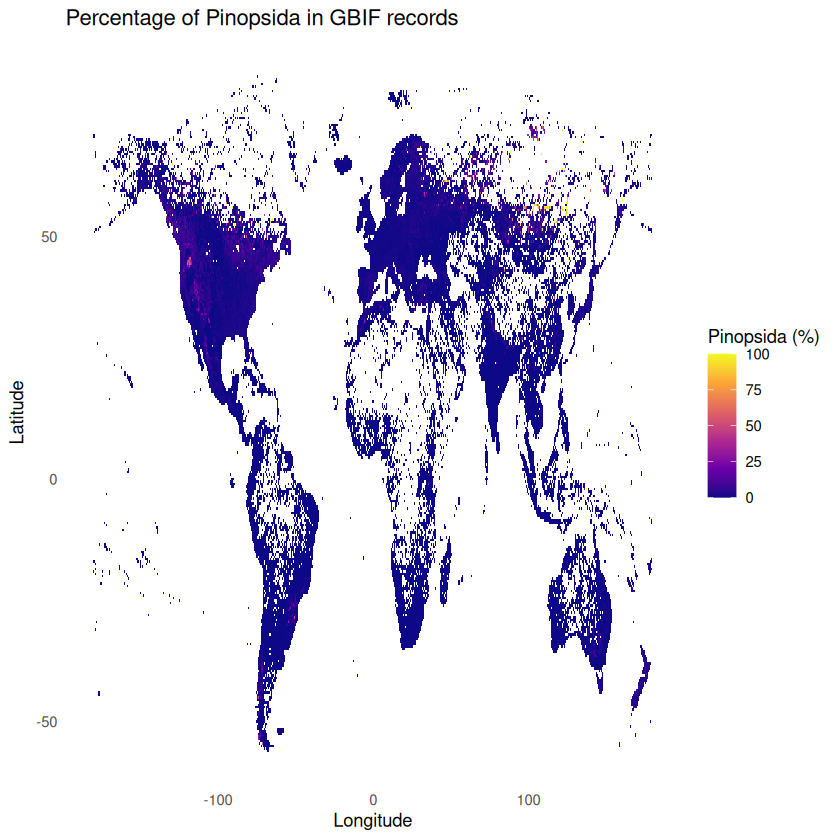

In [7]:
# plot percentage of class=="Pinopsida" per grid cell at 0.5 degree resolution
gbif[, grid_cell := paste0(floor(decimalLatitude*2)/2, "_",floor(decimalLongitude*2)/2)]
gbif[, pinopsida := class == "Pinopsida"]
gbif_summary <- gbif[, .(pinopsida_percentage = mean(pinopsida)*100), by = grid_cell]
gbif_summary[, c("lat", "lon") := tstrsplit(grid_cell, "_", fixed = TRUE)]
gbif_summary[, lat := as.numeric(lat)]
gbif_summary[, lon := as.numeric(lon)]  
library(ggplot2)
ggplot(gbif_summary, aes(x = lon, y = lat, fill = pinopsida_percentage)) +
  geom_tile() +
  scale_fill_viridis_c(option = "plasma", na.value = "grey90") +
  labs(title = "Percentage of Pinopsida in GBIF records",
  x = "Longitude", y = "Latitude", fill = "Pinopsida (%)") + 
    theme_minimal() +
    theme(panel.grid = element_blank())
    

In [ ]:
TRY <- fread("../Data/TRY/TRY6_gapfilled_for_distribution/TRY6_gapfilled_filtered_2.csv")

head(TRY)

## Longevity

In [4]:
gbif <- fread("/net/data/GBIF/2025_06_15_cit_science_only/0047329-250525065834625.csv", select = c("gbifID", "class", "scientificName", "decimalLatitude", "decimalLongitude"))

Warning message in fread("/net/data/GBIF/2025_06_15_cit_science_only/0047329-250525065834625.csv", :
“Found and resolved improper quoting out-of-sample. First healed line 10242: <<3352676798	0a013f89-5381-4578-9d82-5f28fd5f1ef6	20890773	Plantae	Tracheophyta	Magnoliopsida	Asterales	Asteraceae	Gnaphalium	Gnaphalium uliginosum		SPECIES	Gnaphalium uliginosum L.	Gnaphalium uliginosum	L.	GB	"the Field", Ballymorran	Northern Ireland	PRESENT		aa569acf-991d-4467-b327-8442f30ddbd2	54.4662	-5.65704	50.0						2021-06-26	26	6	2021	5390848	5390848	HUMAN_OBSERVATION		iRecord | App			Dalzell, Jake		CC_BY_4_0	Botanical Society of Britain and Ireland and Biological Records Centre	Dalzell, >>. If the fields are not quoted (e.g. field separator does not appear within any field), try quote="" to avoid this warning.”


In [5]:
head(gbif)

gbifID,class,scientificName,decimalLatitude,decimalLongitude
<int64>,<chr>,<chr>,<dbl>,<dbl>
3352641301,Magnoliopsida,Matricaria discoidea DC.,56.14011,-3.369429
4951294464,Liliopsida,Deschampsia cespitosa (L.) P.Beauv.,54.97456,-1.634406
4866764380,Magnoliopsida,Quercus robur L.,54.99222,-1.540470
3098399480,Magnoliopsida,Myriophyllum verticillatum L.,52.75213,1.511204
3352641302,Polypodiopsida,Asplenium trichomanes L.,56.00960,-3.388866
5158856302,Magnoliopsida,Primula veris L.,51.60241,-1.122803


In [19]:
dim(gbif)

[1] 75261670        5

In [20]:
length(unique(gbif$gbifID))

[1] 75261670

In [6]:
# read ~/Func_Neo_Phytes/Data/TRY/47270_17022026112317/47270_longevity_categorical.csv
longevity_cat <- fread("~/Func_Neo_Phytes/Data/TRY/47270_17022026112317/47270_longevity_categorical.csv")
head(longevity_cat)

AccSpeciesName,OrigValueStr
<chr>,<chr>
Achillea millefolium,perennial
Angelica sylvestris,perennial
Anthriscus sylvestris,perennial
Bartsia alpina,perennial
Caltha palustris,perennial
Epilobium angustifolium,perennial


In [7]:
dim(longevity_cat)


[1] 23978     2

In [8]:
length(unique(longevity_cat$AccSpeciesName))

[1] 21254

In [9]:
# print rows with non-unique AccSpeciesName, sorted by AccSpeciesName
longevity_cat[duplicated(AccSpeciesName) | duplicated(AccSpeciesName, fromLast = TRUE)][order(AccSpeciesName)]


AccSpeciesName,OrigValueStr
<chr>,<chr>
ADIANTUM CAPILLUS-VENERIS,Perennial
ADIANTUM CAPILLUS-VENERIS,perennial
ALISMA PLANTAGO-AQUATICA,Perennial
ALISMA PLANTAGO-AQUATICA,perennial
APERA SPICA-VENTI,annual
APERA SPICA-VENTI,Annual
ATROPA BELLA-DONNA,perennial
ATROPA BELLA-DONNA,Perennial
Abies concolor,Perennial


In [10]:
# make all values in "OrigValueStr" lowercase and remove leading/trailing whitespace
longevity_cat[, OrigValueStr := tolower(trimws(OrigValueStr))]  


In [11]:
# keep only unique rows in longevity_cat
longevity_cat <- unique(longevity_cat)
dim(longevity_cat)

[1] 21543     2

In [12]:
# remove rows with non-unique AccSpeciesName, sorted by AccSpeciesName
longevity_cat <- longevity_cat[!(duplicated(AccSpeciesName) | duplicated(AccSpeciesName, fromLast = TRUE))][order(AccSpeciesName)]
dim(longevity_cat)

[1] 20965     2

In [13]:
length(unique(longevity_cat$AccSpeciesName))

[1] 20965

In [14]:
longevity_cat[, AccSpeciesName := sapply(strsplit(AccSpeciesName, " "), function(x) paste(head(x, 2), collapse = " "))]
gbif[, scientificName := sapply(strsplit(scientificName, " "), function(x) paste(head(x, 2), collapse = " "))]
longevity_match <- gbif[longevity_cat, on = .(scientificName = AccSpeciesName), nomatch = 0]

head(longevity_match)

gbifID,class,scientificName,decimalLatitude,decimalLongitude,OrigValueStr
<int64>,<chr>,<chr>,<dbl>,<dbl>,<chr>
3953207613,Magnoliopsida,Abelmoschus esculentus,24.588762,73.70106,annual
3958247572,Magnoliopsida,Abelmoschus esculentus,33.915203,-81.24768,annual
3958343922,Magnoliopsida,Abelmoschus esculentus,35.085275,-81.20518,annual
3954387343,Magnoliopsida,Abelmoschus esculentus,-9.307185,28.74103,annual
3954909760,Magnoliopsida,Abelmoschus esculentus,35.041740,-85.35838,annual
3956039327,Magnoliopsida,Abelmoschus esculentus,41.970919,-88.33913,annual


In [15]:
dim(longevity_match)

[1] 62116290        6

In [21]:
# remove rows with duplicate gbifID, keep only the first occurrence
longevity_match_unique <- longevity_match[!duplicated(gbifID)]
dim(longevity_match_unique)

[1] 52645732        6

In [22]:
# get number of unique gbifID in longevity_match
length(unique(longevity_match$gbifID))

[1] 52645732

In [24]:
# write longevity_match to "/net/scratch/swolf/GBIF/gbif_h3/res3_res4_cs_longevity.csv"
fwrite(longevity_match_unique, "/net/scratch/swolf/GBIF/gbif_h3/longevity.csv")

In [25]:
library(data.table)
library(h3)

# Set parameters
resolution_3 <- 3  # H3 resolution level 3
#resolution_4 <- 4  # H3 resolution level 4
chunk_size <- 1e4  # Process data in 1 million row chunks

# Output file path
#output_file <- "/net/scratch/swolf/GBIF/gbif_h3/res3_res4.csv"
output_file <- "/net/scratch/swolf/GBIF/gbif_h3/res3_cs_longevity.csv"

# Ensure the dataset is a data.table
gbif_dt_filtered <- longevity_match_unique
setDT(gbif_dt_filtered)

# Remove existing output file to prevent appending issues
if (file.exists(output_file)) {
    file.remove(output_file)
}

# Get total rows
total_rows <- nrow(gbif_dt_filtered)

# Process data in chunks
for (start_row in seq(1, total_rows, by = chunk_size)) {
    # Determine end row for the current chunk
    end_row <- min(start_row + chunk_size - 1, total_rows)
    
    # Extract the chunk
    chunk <- gbif_dt_filtered[start_row:end_row]
    
    # Apply geo_to_h3 function and store results for both resolutions
    chunk[, h3_res3 := geo_to_h3(c(decimalLatitude, decimalLongitude), resolution_3)]
    #chunk[, h3_res4 := geo_to_h3(c(decimalLatitude, decimalLongitude), resolution_4)]
    
    # Save the processed chunk (append mode)
    fwrite(chunk, output_file, append = TRUE)
    
    # Print progress
    cat("Processed rows:", start_row, "to", end_row, "\n")
}

# Optional: Load the processed results back into a data.table if needed
# processed_data <- fread(output_file)


Processed rows: 1 to 10000 
Processed rows: 10001 to 20000 
Processed rows: 20001 to 30000 
Processed rows: 30001 to 40000 
Processed rows: 40001 to 50000 
Processed rows: 50001 to 60000 
Processed rows: 60001 to 70000 
Processed rows: 70001 to 80000 
Processed rows: 80001 to 90000 
Processed rows: 90001 to 1e+05 
Processed rows: 100001 to 110000 
Processed rows: 110001 to 120000 
Processed rows: 120001 to 130000 
Processed rows: 130001 to 140000 
Processed rows: 140001 to 150000 
Processed rows: 150001 to 160000 
Processed rows: 160001 to 170000 
Processed rows: 170001 to 180000 
Processed rows: 180001 to 190000 
Processed rows: 190001 to 2e+05 
Processed rows: 200001 to 210000 
Processed rows: 210001 to 220000 
Processed rows: 220001 to 230000 
Processed rows: 230001 to 240000 
Processed rows: 240001 to 250000 
Processed rows: 250001 to 260000 
Processed rows: 260001 to 270000 
Processed rows: 270001 to 280000 
Processed rows: 280001 to 290000 
Processed rows: 290001 to 3e+05 
Proces

In [26]:
# read /net/scratch/swolf/GBIF/gbif_h3/res3_cs_longevity.csv
gbif_longevity <- fread("/net/scratch/swolf/GBIF/gbif_h3/res3_cs_longevity.csv")

In [27]:
head(gbif_longevity)

gbifID,class,scientificName,decimalLatitude,decimalLongitude,OrigValueStr,h3_res3
<int64>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>
3953207613,Magnoliopsida,Abelmoschus esculentus,24.588762,73.70106,annual,833db6fffffffff
3958247572,Magnoliopsida,Abelmoschus esculentus,33.915203,-81.24768,annual,8344dcfffffffff
3958343922,Magnoliopsida,Abelmoschus esculentus,35.085275,-81.20518,annual,8344d8fffffffff
3954387343,Magnoliopsida,Abelmoschus esculentus,-9.307185,28.74103,annual,83961afffffffff
3954909760,Magnoliopsida,Abelmoschus esculentus,35.041740,-85.35838,annual,8344cdfffffffff
3956039327,Magnoliopsida,Abelmoschus esculentus,41.970919,-88.33913,annual,832759fffffffff


In [28]:
# aggregate numer of occurrences at h3 res 3 level, with OrigValueStr== "annual", and number of  OrigValueStr== "perennial"
aggregated_longevity <- gbif_longevity[, .(annual_count = sum(OrigValueStr == "annual"),
                                     perennial_count = sum(OrigValueStr == "perennial")), by = h3_res3]
head(aggregated_longevity)

h3_res3,annual_count,perennial_count
<chr>,<int>,<int>
833db6fffffffff,46,105
8344dcfffffffff,656,4826
8344d8fffffffff,2378,15292
83961afffffffff,2,15
8344cdfffffffff,4109,32985
832759fffffffff,11364,136883


In [29]:
# calculate percentage of annual and perennial occurrences per h3_res3 cell
aggregated_longevity[, total_count := annual_count + perennial_count]
aggregated_longevity[, annual_percentage := (annual_count / total_count) * 100]
aggregated_longevity[, perennial_percentage := (perennial_count / total_count) * 100]
head(aggregated_longevity)

h3_res3,annual_count,perennial_count,total_count,annual_percentage,perennial_percentage
<chr>,<int>,<int>,<int>,<dbl>,<dbl>
833db6fffffffff,46,105,151,30.463576,69.53642
8344dcfffffffff,656,4826,5482,11.966436,88.03356
8344d8fffffffff,2378,15292,17670,13.457838,86.54216
83961afffffffff,2,15,17,11.764706,88.23529
8344cdfffffffff,4109,32985,37094,11.077263,88.92274
832759fffffffff,11364,136883,148247,7.665585,92.33441


In [30]:
# save aggregated_longevity to "/net/scratch/swolf/GBIF/gbif_h3/aggregated_longevity.csv"
fwrite(aggregated_longevity, "/net/scratch/swolf/GBIF/gbif_h3/aggregated_longevity.csv")

In [ ]:
# aggregat at h3 res 3 level the number of occurrences
aggregated_res3 <- gbif_longevity[, .N, by = h3_res3]
head(aggregated_res3)

## Filter CS data for Conifers

In [ ]:
# filter for class== "Pinopsida"
gbif <- gbif[class == "Pinopsida"]

In [ ]:
# write filtered data to file
fwrite(gbif, "/net/home/swolf/Func_Neo_Phytes/Data/gbif_cit_pinopsida.csv")

In [ ]:
#read "/net/home/swolf/Func_Neo_Phytes/Data/gbif_cit_pinopsida.csv"
gbif_pinopsida <- fread("/net/home/swolf/Func_Neo_Phytes/Data/gbif_cit_pinopsida.csv")

In [ ]:
head(gbif_pinopsida)

gbifID,class,decimalLatitude,decimalLongitude,pinopsida_rec,grid_cell,pinopsida
<int64>,<chr>,<dbl>,<dbl>,<lgl>,<chr>,<lgl>
5158831791,Pinopsida,51.02842,-0.550441,TRUE,51_-1,TRUE
3098399614,Pinopsida,53.37906,-2.869668,TRUE,53_-3,TRUE
4981254867,Pinopsida,51.90967,1.039679,TRUE,51.5_1,TRUE
5158856308,Pinopsida,52.55995,-3.801039,TRUE,52.5_-4,TRUE
3785860316,Pinopsida,55.15925,-1.860290,TRUE,55_-2,TRUE
4466212380,Pinopsida,51.97897,-2.838575,TRUE,51.5_-3,TRUE


In [ ]:
library(data.table)
library(h3)

# Set parameters
resolution_3 <- 3  # H3 resolution level 3
resolution_4 <- 4  # H3 resolution level 4
chunk_size <- 1e4  # Process data in 1 million row chunks

# Output file path
#output_file <- "/net/scratch/swolf/GBIF/gbif_h3/res3_res4.csv"
output_file <- "/net/scratch/swolf/GBIF/gbif_h3/res3_res4_cs_conifers.csv"

# Ensure the dataset is a data.table
gbif_dt_filtered <- gbif_pinopsida
setDT(gbif_dt_filtered)

# Remove existing output file to prevent appending issues
if (file.exists(output_file)) {
    file.remove(output_file)
}

# Get total rows
total_rows <- nrow(gbif_dt_filtered)

# Process data in chunks
for (start_row in seq(1, total_rows, by = chunk_size)) {
    # Determine end row for the current chunk
    end_row <- min(start_row + chunk_size - 1, total_rows)
    
    # Extract the chunk
    chunk <- gbif_dt_filtered[start_row:end_row]
    
    # Apply geo_to_h3 function and store results for both resolutions
    chunk[, h3_res3 := geo_to_h3(c(decimalLatitude, decimalLongitude), resolution_3)]
    chunk[, h3_res4 := geo_to_h3(c(decimalLatitude, decimalLongitude), resolution_4)]
    
    # Save the processed chunk (append mode)
    fwrite(chunk, output_file, append = TRUE)
    
    # Print progress
    cat("Processed rows:", start_row, "to", end_row, "\n")
}

# Optional: Load the processed results back into a data.table if needed
# processed_data <- fread(output_file)


Processed rows: 1 to 10000 
Processed rows: 10001 to 20000 
Processed rows: 20001 to 30000 
Processed rows: 30001 to 40000 
Processed rows: 40001 to 50000 
Processed rows: 50001 to 60000 
Processed rows: 60001 to 70000 
Processed rows: 70001 to 80000 
Processed rows: 80001 to 90000 
Processed rows: 90001 to 1e+05 
Processed rows: 100001 to 110000 
Processed rows: 110001 to 120000 
Processed rows: 120001 to 130000 
Processed rows: 130001 to 140000 
Processed rows: 140001 to 150000 
Processed rows: 150001 to 160000 
Processed rows: 160001 to 170000 
Processed rows: 170001 to 180000 
Processed rows: 180001 to 190000 
Processed rows: 190001 to 2e+05 
Processed rows: 200001 to 210000 
Processed rows: 210001 to 220000 
Processed rows: 220001 to 230000 
Processed rows: 230001 to 240000 
Processed rows: 240001 to 250000 
Processed rows: 250001 to 260000 
Processed rows: 260001 to 270000 
Processed rows: 270001 to 280000 
Processed rows: 280001 to 290000 
Processed rows: 290001 to 3e+05 
Proces

In [ ]:
# read "/net/scratch/swolf/GBIF/gbif_h3/res3_res4_cs_conifers.csv"
processed_data <- fread("/net/scratch/swolf/GBIF/gbif_h3/res3_res4_cs_conifers.csv")
head(processed_data)


gbifID,class,decimalLatitude,decimalLongitude,pinopsida_rec,grid_cell,pinopsida,h3_res3,h3_res4
<int64>,<chr>,<dbl>,<dbl>,<lgl>,<chr>,<lgl>,<chr>,<chr>
5158831791,Pinopsida,51.02842,-0.550441,TRUE,51_-1,TRUE,83194afffffffff,84194a5ffffffff
3098399614,Pinopsida,53.37906,-2.869668,TRUE,53_-3,TRUE,831951fffffffff,8419511ffffffff
4981254867,Pinopsida,51.90967,1.039679,TRUE,51.5_1,TRUE,83194efffffffff,84194ebffffffff
5158856308,Pinopsida,52.55995,-3.801039,TRUE,52.5_-4,TRUE,83195efffffffff,84195e1ffffffff
3785860316,Pinopsida,55.15925,-1.860290,TRUE,55_-2,TRUE,831973fffffffff,8419731ffffffff
4466212380,Pinopsida,51.97897,-2.838575,TRUE,51.5_-3,TRUE,831958fffffffff,841958dffffffff


In [ ]:
# aggregat at h3 res 3 level the number of occurrences
aggregated_res3 <- processed_data[, .N, by = h3_res3]
head(aggregated_res3)

h3_res3,N
<chr>,<int>
83194afffffffff,2120
831951fffffffff,1049
83194efffffffff,520
83195efffffffff,460
831973fffffffff,584
831958fffffffff,837


In [ ]:
# write file: aggregated_res3 to "/net/scratch/swolf/GBIF/gbif_h3/aggregated_res3_conifers.csv"
fwrite(aggregated_res3, "/net/scratch/swolf/GBIF/gbif_h3/aggregated_res3_conifers.csv")


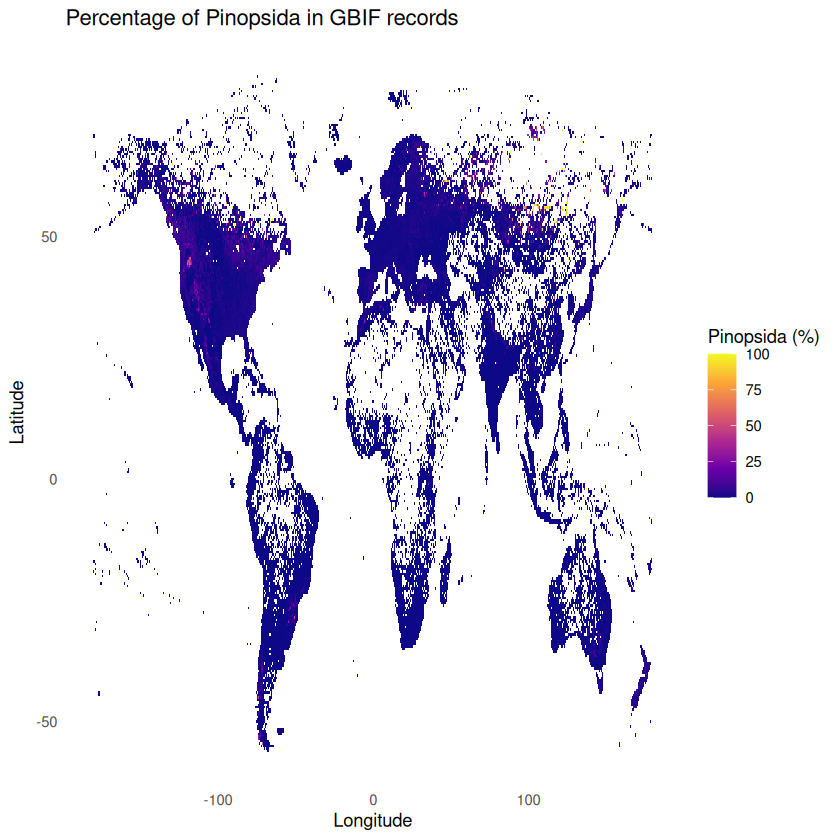

In [ ]:
# plot percentage of class=="Pinopsida" per grid cell at 0.5 degree resolution
gbif[, grid_cell := paste0(floor(decimalLatitude*2)/2, "_",floor(decimalLongitude*2)/2)]
gbif[, pinopsida := class == "Pinopsida"]
gbif_summary <- gbif[, .(pinopsida_percentage = mean(pinopsida)*100), by = grid_cell]
gbif_summary[, c("lat", "lon") := tstrsplit(grid_cell, "_", fixed = TRUE)]
gbif_summary[, lat := as.numeric(lat)]
gbif_summary[, lon := as.numeric(lon)]  
library(ggplot2)
ggplot(gbif_summary, aes(x = lon, y = lat, fill = pinopsida_percentage)) +
  geom_tile() +
  scale_fill_viridis_c(option = "plasma", na.value = "grey90") +
  labs(title = "Percentage of Pinopsida in GBIF records",
  x = "Longitude", y = "Latitude", fill = "Pinopsida (%)") + 
    theme_minimal() +
    theme(panel.grid = element_blank())
    